In [4]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
from scipy import stats
from src.data import load_data
from src.config import CV_DIR
from src.pipelines import get_final
from src.experiment_log import ExperimentLogger

# Tải dữ liệu train và khởi tạo logger cho thí nghiệm D
X_train, _, y_train, _, labels = load_data()
lg = ExperimentLogger("Khanh")

# Tìm các cột liên quan đến cổng (port)
cong = []
for c in X_train.columns:
    if c in ("id.orig_p", "id.resp_p"):
        cong.append(c)

# Tìm các cột bắt đầu bằng proto hoặc service
proto_service = []
for c in X_train.columns:
    if c.startswith("proto") or c.startswith("service"):
        proto_service.append(c)

print("Cong:", cong)
print("Proto va service:", proto_service)

# Các biến thể thử nghiệm bỏ bớt nhóm đặc trưng
bien_the = {
    "final_bo_cong": cong,
    "final_bo_proto_service": proto_service,
    "final_bo_cong_va_proto_service": cong + proto_service,
}

for ten, bo in bien_the.items():
    X_sub = X_train.drop(columns=bo)
    model = get_final()
    ghi_chu = "bo " + str(len(bo)) + " cot"
    lg.run(
        model,
        X_sub,
        y_train,
        ten,
        strategy="class_weight=balanced",
        notes=ghi_chu,
    )

Cong: ['id.orig_p', 'id.resp_p']
Proto va service: ['proto_icmp', 'proto_tcp', 'proto_udp', 'service_-', 'service_dhcp', 'service_dns', 'service_http', 'service_irc', 'service_mqtt', 'service_ntp', 'service_radius', 'service_ssh', 'service_ssl']


In [5]:
def kiem_dinh_cap(ten_goc, ten_khac):
    # Đọc điểm macro_f1 theo từng fold của mô hình gốc và biến thể
    df_goc = pd.read_csv(CV_DIR / f"{ten_goc}.csv")
    df_khac = pd.read_csv(CV_DIR / f"{ten_khac}.csv")

    a = df_goc["macro_f1"].to_numpy()
    b = df_khac["macro_f1"].to_numpy()

    # Độ chênh lệch giữa biến thể và mô hình gốc trên từng fold
    d = b - a
    k = len(d)
    chenh_tb = d.mean()

    # Phương sai mẫu hiệu chỉnh (ddof=1) và công thức t-test có hiệu chỉnh Nadeau-Bengio
    var_d = d.var(ddof=1)
    sai_so_chuan = np.sqrt((1.0 / k + 0.25) * var_d)
    t_stat = chenh_tb / sai_so_chuan

    # Kiểm định 2 phía với bậc tự do df = k - 1
    p_val = 2 * (1.0 - stats.t.cdf(abs(t_stat), df=k - 1))

    return round(chenh_tb, 4), round(t_stat, 2), round(p_val, 3)


danh_sach_ten = ["hgb_N1_balanced"] + list(bien_the.keys())
rows = []

for ten in danh_sach_ten:
    cv = pd.read_csv(CV_DIR / f"{ten}.csv")

    if ten == "hgb_N1_balanced":
        ch = 0
        t_val = 0
        p_val = 1
    else:
        ch, t_val, p_val = kiem_dinh_cap("hgb_N1_balanced", ten)

    thong_tin = {
        "bien_the": ten,
        "macro_f1": round(cv["macro_f1"].mean(), 4),
        "std": round(cv["macro_f1"].std(), 4),
        "chenh_so_voi_day_du": ch,
        "t": t_val,
        "p": p_val,
        "recall_c4": round(cv["recall_c4"].mean(), 3),
        "recall_c5": round(cv["recall_c5"].mean(), 3),
        "recall_c11": round(cv["recall_c11"].mean(), 3),
    }
    rows.append(thong_tin)

bang = pd.DataFrame(rows)
bang.to_csv(CV_DIR / "ablation_ports.csv", index=False)
bang

,bien_the,macro_f1,std,chenh_so_voi_day_du,t,p,recall_c4,recall_c5,recall_c11
0,hgb_N1_balanced,0.9633,0.0127,0.0000,0.00,1.000,0.727,0.82,0.966
1,final_bo_cong,0.9539,0.0128,-0.0094,-3.86,0.018,0.727,0.82,0.960
2,final_bo_proto_service,0.9656,0.0124,0.0024,1.17,0.308,0.727,0.82,0.960
3,final_bo_cong_va_proto_service,0.9495,0.0125,-0.0138,-18.04,0.000,0.727,0.82,0.931


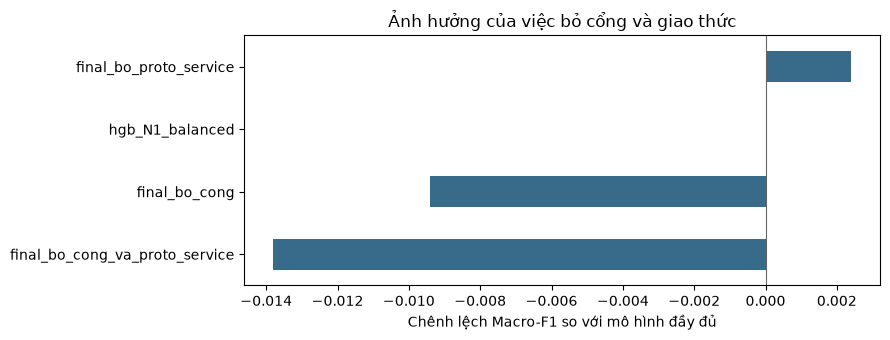

In [6]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

results = (Path('..') if Path.cwd().name == 'experiments' else Path('.')) / 'results'
values = pd.read_csv(results / 'cv/ablation_ports.csv').set_index('bien_the')['chenh_so_voi_day_du']
fig, ax = plt.subplots(figsize=(9, 3.5))
values.sort_values().plot.barh(ax=ax, color='#386A89')
ax.axvline(0, color='0.4', linewidth=0.8)
ax.set(title='Ảnh hưởng của việc bỏ cổng và giao thức', xlabel='Chênh lệch Macro-F1 so với mô hình đầy đủ', ylabel='')
fig.tight_layout()
(results / 'figures').mkdir(exist_ok=True)
fig.savefig(results / 'figures/ablation_ports.png', dpi=300, bbox_inches='tight')
plt.show()